# Bike Sharing Project

Your task is to **predict how many bikes are rented in an hour** in the Capital Bikeshare system of Washington, D.C., and to find out how far **ensemble methods** improve on a single decision tree and on a linear model. In the project you combine everything you learned this week, from decision trees to boosting, voting and stacking, into one complete analysis.

The task below follows the steps of a machine learning project, in a single pass:

![The project in one pass, from top to bottom: 1. goal and metric, 2. get the data, 3. a train-test split into training data and locked test data. Steps 4 and 5 (explore, baselines) use only the training data. Steps 6 and 7 form the model selection loop: feature engineering, set hyperparameters, train model(s) and calculate the cross-validation score, then repeat. In step 8, the test data is unlocked, the models are scored on the test set and the hours with the largest errors are examined](assets/bike_sharing_project_workflow.png)

# The Business Problem

The operations team of Capital Bikeshare plans its work hour by hour: how many bikes have to be available, how many trucks move bikes between stations, and how many staff are on duty. To plan, they need to know **how many bikes are rented in an hour under given conditions**: the time of day, the type of day, the season and the weather. A Tuesday at 17:00 in summer needs very different planning from a rainy Sunday morning in January.

Your model answers this question: given the conditions of an hour, it predicts its rentals. The more accurate it is, the better the team can plan, so you compare several models and choose the best one. At the end, you look at **where the model makes its biggest mistakes**, so that the team knows when they can trust its numbers and when not.

The model describes typical hours under given conditions; it is not used to forecast particular future dates. The hours you hold back as a test set can therefore be drawn **at random** from the whole period. A forecast would be a different problem: there the model has to predict hours that come after everything it was trained on, so the test set would have to be the most recent hours.

# Data Description

The data covers **two years, October 2024 to September 2026**, and ships with this repository as one table, `data/bike_sharing.csv`, with **one row per hour**. It combines three sources:

- the number of bikes rented in each hour, from the trip records that [Capital Bikeshare](https://capitalbikeshare.com/system-data) publishes. Every trip is counted in the hour in which it started;
- the weather in central Washington, D.C. in each hour, from the [Open-Meteo](https://open-meteo.com/) historical weather archive;
- the public holidays of Washington, D.C.

| Column | Source | Description |
| :-- | :-- | :-- |
| `datetime` | | start of the hour, local time in Washington, D.C. |
| `casual` | rentals | rentals by casual riders, who pay per ride or per day |
| `member` | rentals | rentals by members with an annual or monthly membership |
| `rentals` | rentals | total number of rentals in the hour, **the prediction target** |
| `temperature` | weather | air temperature in °C |
| `feels_like` | weather | apparent ("feels like") temperature in °C, which accounts for wind and humidity |
| `humidity` | weather | relative humidity in % |
| `precipitation` | weather | rain and snow in the hour, in mm of water |
| `snowfall` | weather | snowfall in the hour, in cm |
| `wind_speed` | weather | wind speed in km/h |
| `cloud_cover` | weather | share of the sky covered by clouds, in % |
| `weather_code` | weather | type of weather as a [WMO code](https://open-meteo.com/en/docs/historical-weather-api): 0 clear, 1 to 3 partly cloudy to overcast, 51 to 55 drizzle, 61 to 65 rain (light to heavy), 71 to 75 snow (light to heavy) |
| `holiday` | holidays | name of the public holiday on that day, empty on all other days |

Rentals data © Capital Bikeshare, used under the [Capital Bikeshare Data License Agreement](https://capitalbikeshare.com/data-license-agreement). Weather data by [Open-Meteo.com](https://open-meteo.com/), licensed [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

## Task

1. **Set your goal.** Decide which metric you use to judge the model, and explain why. Think about what the operations team needs to read from it.
2. **Get the data.** Load `data/bike_sharing.csv`, and take a first look at its size and columns. Turn `datetime` into a date type, so that you can extract the hour, the weekday or the month from it later.
3. **Split the data into a training and a test set.** Use `train_test_split` once. Choose the size of the test set with `test_size`, and fix the `random_state`, so that you get the same split every time you run the notebook. Keep the features and the target together: the result should be two DataFrames, `df_train` and `df_test`, that both still contain the `rentals` column. In step 7, cross-validation on the training set takes the place of a validation set. Do not look at `df_test` until step 8.
4. **Explore the training set.** How do the rentals change over the day, and is that pattern the same on working days, weekends and holidays? How do the weather columns relate to the rentals? Which columns contain the same information? Check every column carefully: **would you know its value for an hour without having counted that hour's rentals?**

> [!IMPORTANT]
> **Keep a record of every change you make to the training data by hand.** In step 8 you apply exactly the same changes to the test set. This covers, for example, new columns such as the hour of the day or a flag for working days that you extract from `datetime` and `holiday`, and every column you drop. Put these changes into a function, so that you can call the same function on the test set. Transformations inside your `Pipeline` (scaling, encoding) are applied to the test set automatically, with the values learned on the training data.

5. **Separate the features from the target, and build two baselines.** Split `df_train` into `X_train` and `y_train`; the test set stays untouched until step 8. Then build two simple models that your models have to beat:
    - a **mean baseline** with [`DummyRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html), which predicts the mean number of rentals of the training set for every hour, and
    - a **rule-based baseline** built from what you found in step 4, that a person could calculate by hand. Learn the values of the rule on the training data.
6. **Train a linear model and a single decision tree.** Train a regularised linear model, for example `Ridge`, in a `Pipeline` with the preprocessing it needs, and a `DecisionTreeRegressor`. Compare them with cross-validation: which one handles the pattern over the day better, and why? Does the tree need the same preprocessing as the linear model?
7. **Build, tune and compare ensembles with cross-validation.** Train at least:
    - a **random forest** (`RandomForestRegressor`),
    - a **gradient boosting model**, for example `XGBRegressor` or `CatBoostRegressor`: for a number, use the regressor and a regression metric. CatBoost can treat columns as categories itself (`cat_features`): find out whether that helps here,
    - and a **combination of models** with `VotingRegressor` or `StackingRegressor`.

    Tune at least one of the models with `RandomizedSearchCV` (or `GridSearchCV`), and choose the best model by its cross-validated score. **Save every model in its own variable** (and the values of your rule), so that you can evaluate all of them in the last step.
8. **Prepare the test set and evaluate all models at the very end.** First apply to `df_test` the changes you made by hand to the training data, and split it into `X_test` and `y_test`. Then calculate the **training and the test scores of every model** with your chosen metric, including both baselines, and collect them in **one table**: one row per model, with columns for the training and the test scores. Compare the models: which ones beat the baselines, how much did each step from the linear model to the ensembles gain, and how large is the difference between training and test scores?

    Finally, find out **where your best model makes its biggest mistakes**, so that the operations team knows when to trust it:
    1. **Calculate the residuals** of the test hours: actual rentals minus predicted rentals. A large positive residual means the model predicted far too few rentals, a large negative one far too many. Use only the test hours: the model has seen the training hours, so its errors there are too small to tell you anything.
    2. **Plot the residuals**: a scatter plot of the residuals against the predicted rentals, with a line at 0, and the size of the residuals by hour of the day (for example a box plot). Where does the model make its largest errors, and do the errors grow with the number of rentals?
    3. **Compare predicted and actual rentals over the day**: plot the mean actual and the mean predicted rentals for each hour of the day, separately for working days and weekends. Does the model reproduce the daily pattern you found in step 4? At which hours does it predict too many or too few rentals on average?
    4. **List the hours with the biggest mistakes**: the 10 hours with the largest positive and the 10 with the largest negative residuals, with their date, time and weather.

> [!TIP]
> If you use `CatBoostRegressor` with `cat_features` inside `cross_val_score` or a search, pass `cat_features` to `.fit()` instead of the constructor (for example `cross_val_score(..., params={"cat_features": [...]})`): set in the constructor, it breaks the copying of the model that cross-validation does.

In [2]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, uniform, loguniform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

## Step 1 – Goal and metric

**Main metric: RMSE (root mean squared error), in bikes per hour.**

The operations team plans bikes, trucks and staff hour by hour. RMSE is in the same unit as the target (bikes), so they can read it directly. Because it squares the errors before averaging, a few big misses weigh much more than many small ones, and a big miss in a busy hour (e.g. no bikes at 17:00 rush hour) costs the team more than several small misses.

I also report two more metrics for context:
- **MAE** (mean absolute error): the typical error in bikes, easy to explain. If RMSE is much larger than MAE, the model is mostly fine but sometimes misses very badly (a few large errors).
- **R²**: how much better the model is than always predicting the mean (1 = perfect, 0 = no better than the mean). It has no unit, so it is useful for comparing models but not for planning.

## Step 2 – Get the data

Load the table and take a first look. `datetime` is read from the CSV as text, so it is converted to a real date type. Only then can `.dt.hour`, `.dt.dayofweek` or `.dt.month` be used later.

Converting the type is allowed before the split: it only changes the format and learns nothing from the data.

In [3]:
# loading the dataset
df = pd.read_csv('data/bike_sharing.csv')

# converting the 'datetime' column to datetime type
df['datetime'] = pd.to_datetime(df['datetime'])

print(f"Dataset shape: {df.shape}")
print(df.dtypes)
df.head()

Dataset shape: (17520, 13)
datetime         datetime64[us]
casual                    int64
member                    int64
rentals                   int64
temperature             float64
feels_like              float64
humidity                  int64
precipitation           float64
snowfall                float64
wind_speed              float64
cloud_cover               int64
weather_code              int64
holiday                     str
dtype: object


,datetime,casual,member,rentals,temperature,feels_like,humidity,precipitation,snowfall,wind_speed,cloud_cover,weather_code,holiday
0,2024-10-01 00:00:00,47,89,136,18.1,19.5,96,0.2,0.0,8.6,100,51,NaN
1,2024-10-01 01:00:00,18,30,48,18.2,19.6,96,0.1,0.0,8.9,100,51,NaN
2,2024-10-01 02:00:00,14,17,31,18.2,19.2,94,0.0,0.0,10.3,100,3,NaN
3,2024-10-01 03:00:00,6,9,15,17.9,18.6,93,0.0,0.0,11.7,100,3,NaN
4,2024-10-01 04:00:00,7,20,27,17.6,18.1,93,0.1,0.0,12.4,100,51,NaN


**Check:** October 2024 to September 2026 is 730 days (no 29 February in 2025 or 2026), and 730 × 24 hours = **17,520 rows**, which matches the shape. There is one row per hour, with no gaps, and the 13 columns match the data description.

## Step 3 – Split into training and test set

- **Random split:** the model describes *typical* hours under given conditions; it does not forecast future dates (see the business problem). So the test hours can be drawn at random from the whole period. For a forecast, the test set would have to be the most recent hours instead.
- **The whole DataFrame is split**, so the features and `rentals` stay together. `X` and `y` are separated later.
- `test_size=0.2`: 20 % (≈ 3,500 hours) for the final test, 80 % for training.
- `random_state=42`: the same split every time the notebook runs.

From here on, everything is done on `df_train` only. `df_test` stays locked until step 8.

In [4]:
# splitting train and test data
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

print(f"train: {df_train.shape}")
print(f"test:  {df_test.shape}")

train: (14016, 13)
test:  (3504, 13)


## Step 4 – Explore the training set

### 4a. Data quality

Checks for missing values, duplicates and impossible values are done **after** the split, on the training set only. Every decision that learns something from the data (how to fill missing values, which outliers to remove, …) must not be influenced by the test set, otherwise the test score looks better than it really is (leakage).

**Missing values**

In [5]:
df_train.isna().sum()

datetime             0
casual               0
member               0
rentals              0
temperature          0
feels_like           0
humidity             0
precipitation        0
snowfall             0
wind_speed           0
cloud_cover          0
weather_code         0
holiday          13550
dtype: int64

Only `holiday` has missing values (13,550 of 14,016 hours). Let's look at the values it does have:

In [6]:
# check the distribution of the 'holiday' column in the training dataset
df_train["holiday"].value_counts()

holiday
Labor Day                               43
Washington's Birthday                   42
New Year's Day                          41
Juneteenth National Independence Day    40
Thanksgiving Day                        39
Independence Day                        39
Veterans Day                            38
Memorial Day                            38
DC Emancipation Day                     38
Christmas Day                           38
Columbus Day                            36
Birthday of Martin Luther King, Jr.     34
Name: count, dtype: int64

**Finding: `NaN` in `holiday` is not missing data; it means "this hour is not on a public holiday".** When there is a holiday, the column holds its name (e.g. "Christmas Day"). 14,016 − 13,550 = 466 holiday hours ≈ 12 holidays × 2 years × 24 hours × 80 % in train, so it fits.

A missing value can mean two different things:

| Kind | Meaning | What to do | Example |
|---|---|---|---|
| Not applicable | the thing didn't happen or doesn't exist | turn it into a 0/1 flag; don't fill it with an average | `holiday` here, `yr_renovated` in King County |
| Truly unknown | there should be a value, but it was not recorded | fill it in (median, most frequent, …) or drop the row | a broken weather sensor |

**Decision: use a flag `is_holiday` (1 = holiday, 0 = not) instead of the holiday name.**
Each holiday name appears on only 2 days in the whole dataset (48 hours, ~38 of them in train). One-hot encoding 12 names would let the model learn those few days by heart (e.g. "it rained on that particular Christmas"), which is overfitting. The flag pools all ~466 holiday hours into one pattern, and month and weekday features will already tell the model much of what the name says.

*Possible extra, if there is time:* add the holiday name as a feature and compare the cross-validated RMSE in step 7. Keep it only if it improves.

**Duplicates**

`df_train.duplicated()` only finds rows where **all 13 columns** are identical. Two rows for the same hour with slightly different numbers would not be found that way, so the `datetime` column is checked on its own too.

In [7]:
# check for fully identical rows in the training dataset
df_train.duplicated().sum()

np.int64(0)

In [8]:
# check for duplicate timestamps in the training dataset
df_train['datetime'].duplicated().sum()

np.int64(0)

**Open question: daylight saving time.** `datetime` is in local time, and Washington, D.C. has daylight saving time. Each spring one hour is skipped (2:00 → 3:00), and each autumn one hour happens twice. Still, there are exactly 17,520 rows and no duplicate timestamps. How did the data handle that?

Look at the night the clocks went forward (9 March 2025). This is only a check, not a modelling decision, so looking at `df` here is fine.

In [9]:
# the hour 02:00 did not exist on the clock that night - what do its rentals show?
df[df["datetime"].dt.strftime("%Y-%m-%d") == "2025-03-09"][["datetime", "rentals"]].head(6)

,datetime,rentals
3816,2025-03-09 00:00:00,309
3817,2025-03-09 01:00:00,214
3818,2025-03-09 02:00:00,0
3819,2025-03-09 03:00:00,155
3820,2025-03-09 04:00:00,61
3821,2025-03-09 05:00:00,54


*TODO: my answer –* what are the rentals at 02:00, and what does that tell me about how the data was built?

**Impossible values**

*TODO:* look for negative numbers, humidity above 100 %, a cloud cover outside 0–100, and similar.

In [10]:
df_train.describe().T

,count,mean,min,25%,50%,75%,max,std
datetime,14016,2025-10-01 05:16:10.119863,2024-10-01 00:00:00,2025-04-01 09:45:00,2025-10-01 01:30:00,2026-04-02 05:15:00,2026-09-30 23:00:00,NaN
casual,14016.0,218.758134,0.0,47.0,158.0,320.0,1593.0,211.07215
member,14016.0,534.566781,0.0,134.0,464.0,813.0,2465.0,449.294812
rentals,14016.0,753.324914,0.0,186.75,639.0,1142.0,3188.0,636.260286
temperature,14016.0,14.102775,-15.0,5.8,15.3,22.7,39.7,10.512618
feels_like,14016.0,12.917559,-19.7,2.3,13.5,24.1,43.9,13.20581
humidity,14016.0,67.78232,15.0,53.0,68.0,84.0,100.0,19.018021
precipitation,14016.0,0.136173,0.0,0.0,0.0,0.0,13.6,0.643516
snowfall,14016.0,0.00442,0.0,0.0,0.0,0.0,2.03,0.064462
wind_speed,14016.0,10.127811,0.0,6.0,9.0,13.3,39.7,5.60369


### 4b. Rentals over the day – *next session*

Question from the task: how do the rentals change over the day, and is that pattern the same on working days, weekends and holidays?

Plan:
1. Work on a copy (`eda = df_train.copy()`), so `df_train` stays clean. The real features are made later in `prepare()`, so that they also get applied to the test set.
2. Temporary columns: `hour` (`.dt.hour`) and `weekday` (`.dt.dayofweek`, 0 = Monday, 6 = Sunday).
3. A column `day_type`: `"working day"` (Monday–Friday and not a holiday) or `"weekend/holiday"`, e.g. with `np.where(...)`.
4. `sns.lineplot(data=eda, x="hour", y="rentals", hue="day_type")`: average rentals per hour, one line per day type.

*Before plotting, write down a guess:* at which hours do I expect peaks on working days? And on weekends?

Still to do in step 4: 4c weather vs. rentals, and 4d redundant columns and **leakage**. Would I know a column's value for an hour without having counted that hour's rentals?

### 4d. Redundant columns and leakage

Which columns contain the same information, and which ones would I only know after counting the rentals of the hour? First the correlations between the numeric columns (lower triangle only, because the matrix is symmetric):

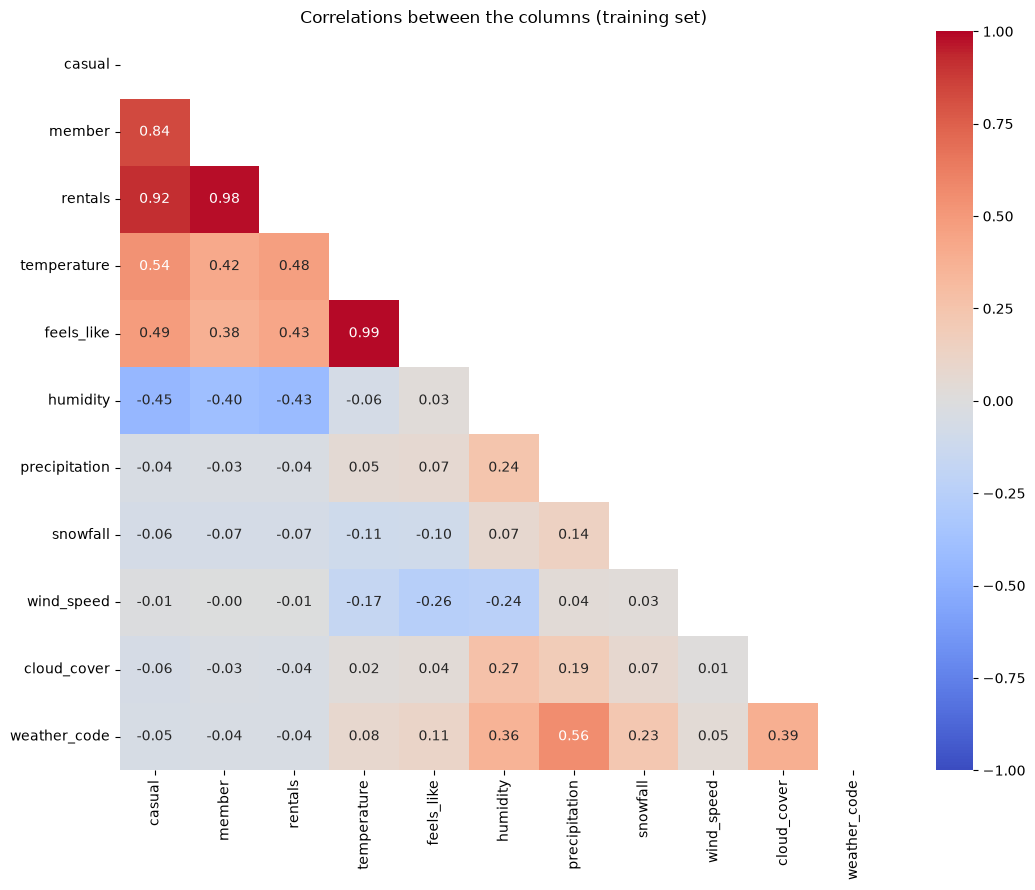

In [23]:
numeric = df_train.select_dtypes("number")
corr = numeric.corr()

# True for the upper triangle and the diagonal -> those cells get hidden
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlations between the columns (training set)")
plt.tight_layout()
plt.show()


Correlation of every column with the target:

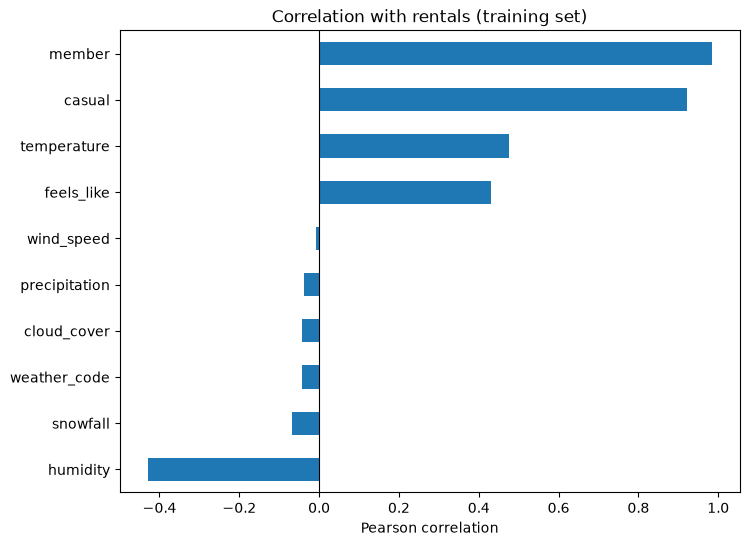

In [22]:
corr_rentals = corr["rentals"].drop("rentals").sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
corr_rentals.plot(kind="barh", ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlation with rentals (training set)")
ax.set_xlabel("Pearson correlation")
plt.show()


**Finding:** two things stand out.
- `temperature` and `feels_like` correlate at **0.99**: they are practically the same column.
- `casual` (0.92) and `member` (0.98) correlate almost perfectly with `rentals`. That is suspicious, so check the leakage question: *would I know their value for an hour without having counted that hour's rentals?*

Both pairs as scatter plots:

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(df_train["temperature"], df_train["feels_like"], alpha=0.1, s=5)
axes[0].set_xlabel("temperature (°C)")
axes[0].set_ylabel("feels_like (°C)")
axes[0].set_title("feels_like vs. temperature (training set)")

axes[1].scatter(df_train["casual"] + df_train["member"], df_train["rentals"], alpha=0.1, s=5)
axes[1].set_xlabel("casual + member")
axes[1].set_ylabel("rentals")
axes[1].set_title("casual + member vs. rentals (training set)")

plt.tight_layout()
plt.show()

# do the two rider groups add up to the target?
same = df_train["casual"] + df_train["member"] == df_train["rentals"]
print(f"casual + member == rentals in {same.mean():.1%} of the hours")

**Decisions:**
- **Drop `feels_like`.** It lies on a narrow band around `temperature` (usually within a few degrees). For `Ridge` two such columns make the coefficients unstable (collinearity), for trees the second one is only redundant. `temperature` is kept: it has the stronger link to rentals (0.48 vs. 0.43) and is easier to explain.
- **Drop `casual` and `member` (leakage).** `casual + member == rentals` in every hour: the points lie exactly on a straight line. They are not features but **the target split into two parts**, known only after counting the rentals of the hour. A model given them would just add them up and look perfect, but it could never be used for planning.

**Is `weather_code` new information?** Which codes exist, and how many hours each:

In [11]:
# which codes exist, and how many hours each
print(df_train["weather_code"].nunique(), "distinct codes")
df_train["weather_code"].value_counts().sort_index()


13 distinct codes


weather_code
0     4702
1     1457
2     1079
3     4700
51    1075
53     326
55      97
61     238
63     168
65      19
71      78
73      49
75      28
Name: count, dtype: int64

For each code, the ranges of the other weather columns:

In [ ]:
df_train.groupby("weather_code")[["precipitation", "snowfall", "cloud_cover"]].agg(["min", "max"])

**Finding:** the ranges do not overlap. Codes 0–3 have no rain or snow and differ only by `cloud_cover` (0–19, 20–49, 50–79, 80–100 %). Drizzle and rain (51–65) are separated by the amount of `precipitation`, and snow (71–75) is every hour with `snowfall` above 0. So `weather_code` is a **binned version of `precipitation`, `snowfall` and `cloud_cover`**.

**Decision: drop `weather_code`.** The other three columns carry the same information in more detail, and a tree can learn the same thresholds from them directly.

### 4e. The target: distribution of `rentals`

How are the rentals per hour distributed? On the left the rentals as they are, on the right after `np.log1p` (log(1 + x), which also works for 0):

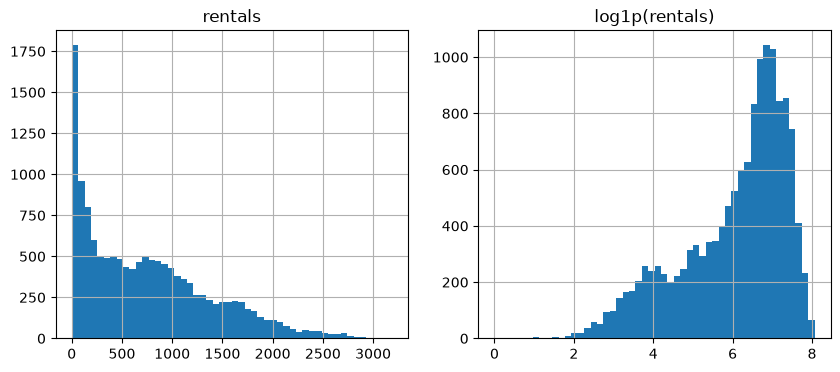

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df_train['rentals'].hist(bins=50, ax=ax[0]); ax[0].set_title('rentals')
np.log1p(df_train['rentals']).hist(bins=50, ax=ax[1]); ax[1].set_title('log1p(rentals)')
plt.show()

In [ ]:
print(f"skewness of rentals:        {df_train['rentals'].skew():.2f}")
print(f"skewness of log1p(rentals): {np.log1p(df_train['rentals']).skew():.2f}")

# the hours with 0 rentals
df_train[df_train["rentals"] == 0][["datetime", "rentals"]]

**Finding:** the rentals are **skewed to the right** (skewness 0.85): many quiet hours (night, cold or wet) and a long tail of busy rush hours up to ≈ 3,200. The mean (753) is above the median (639). `log1p` squeezes the tail, but here it overdoes it: the log version is skewed to the **left** (−0.91), with a tail of quiet night hours.

Only **2 hours** in the training set have 0 rentals, both at 02:00 on the night the clocks go forward (see the daylight saving check in 4a).

**Decisions:**
- **Remove the hours that do not exist because of daylight saving time** (02:00 on the second Sunday of March). Their 0 rentals are not quiet hours but artefacts of the clock change. The rows are found by their **date and time**, not by `rentals == 0`: the rule must not use the target (see the explanation after `remove_nonexistent_hours()` below).
- **Train on `log1p(rentals)`.** The model learns relative differences (+10 % in a quiet hour counts as much as +10 % at rush hour), and the large rush hours dominate the fit less. The predictions are converted back with `np.expm1`, so the RMSE stays in bikes per hour. Because the log over-corrects the skew, the cross-validation in step 6/7 checks whether it really beats the raw target.

A tree does not need a symmetric target; the transformation matters most for the linear model.

### 4f. Calendar features from `datetime`

`datetime` itself cannot go into a model, so the information in it is turned into columns: `hour`, `day_of_week`, `is_weekend` and `season`. The hour of the day is the question of 4b; here the day of the week and the season:

In [ ]:
# meteorological seasons: whole months, the same for every year
SEASONS = {12: "winter", 1: "winter", 2: "winter",
           3: "spring", 4: "spring", 5: "spring",
           6: "summer", 7: "summer", 8: "summer",
           9: "autumn", 10: "autumn", 11: "autumn"}
season_order = ["winter", "spring", "summer", "autumn"]

calendar = df_train[["datetime", "rentals"]].copy()
calendar["day_of_week"] = calendar["datetime"].dt.dayofweek   # 0 = Monday, 6 = Sunday
calendar["is_weekend"] = (calendar["day_of_week"] >= 5).astype(int)
calendar["season"] = calendar["datetime"].dt.month.map(SEASONS)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(data=calendar, x="day_of_week", y="rentals", hue="is_weekend",
            dodge=False, errorbar=None, ax=axes[0])
axes[0].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[0].set_title("Mean rentals per hour by day of the week (training set)")
axes[0].set_ylabel("mean rentals per hour")

sns.boxplot(data=calendar, x="season", y="rentals", order=season_order, ax=axes[1])
axes[1].set_title("Rentals per hour by season (training set)")
axes[1].set_ylabel("rentals per hour")

plt.tight_layout()
plt.show()

calendar.groupby("season")["rentals"].agg(["count", "mean", "median"]).loc[season_order].round()

**Findings:**
- **Day of the week:** the mean rentals per hour are almost the same on every day (≈ 690–800). Weekends do not have fewer rentals in total; Saturday even has the highest mean. So `is_weekend` matters through the **shape** of the day (when people ride), not through the level, which is what 4b looks at.
- **Season:** winter is clearly the quietest season, with a median of ≈ 330 rentals per hour, less than half of the other seasons. Spring (≈ 720), summer (≈ 880) and autumn (≈ 770) are much closer to each other. The season partly overlaps with `temperature`, so cross-validation shows how much it adds.

### Record of manual changes

The task asks to keep a record of every change made to the training data by hand, so that exactly the same changes can be applied to the test set in step 8. Most of them go into one function, `engineer_features()`, that runs as the first step of every `Pipeline`, so it is applied to the test set automatically.

**In `engineer_features()`** (columns only, learns nothing from the data):
1. `is_holiday` = 1 if `holiday` is not NaN, else 0 (`.notna().astype(int)`), an integer instead of a text column. Then drop `holiday`.
2. Drop `feels_like`: almost one to one with `temperature` (r = 0.99, 4d).
3. Drop `weather_code`: a binned version of `precipitation`, `snowfall` and `cloud_cover` (4d).
4. Drop `casual` and `member`: together they are the target (**leakage**, 4d).
5. New columns from `datetime` (4f): `hour`, `day_of_week` (0 = Monday), `is_weekend` (1 = Saturday or Sunday) and `season` (winter = Dec–Feb, spring = Mar–May, summer = Jun–Aug, autumn = Sep–Nov). Then drop `datetime`.

**Outside the pipeline:**

6. Remove the hours that do not exist because of daylight saving time (02:00 on the second Sunday of March, 4a/4e), with `remove_nonexistent_hours()`. The rule uses only the date and time, not the rentals. It is outside the pipeline because a pipeline step can only change columns, not drop rows.
7. Train on `log1p(rentals)` instead of `rentals` (4e). The model is wrapped in a `TransformedTargetRegressor`, which converts the predictions back with `expm1`, so the RMSE stays in bikes per hour.

### Feature engineering function for the pipeline

`engineer_features()` takes the raw columns of a DataFrame (without `rentals`) and returns the model features. It learns nothing from the data, so it can run inside a `Pipeline` as a `FunctionTransformer` and is applied in the same way to the training folds, the test set and any new hour. `casual` and `member` are dropped with `errors="ignore"`, because new data for planning will not have them.

In [ ]:
def engineer_features(X):
    """All column changes from step 4, as the first step of a pipeline."""
    X = X.copy()
    dt = X["datetime"]

    # 1. holiday name -> 0/1 flag (an integer, no text left)
    X["is_holiday"] = X["holiday"].notna().astype(int)

    # 5. calendar features from datetime
    X["hour"] = dt.dt.hour
    X["day_of_week"] = dt.dt.dayofweek                    # 0 = Monday, 6 = Sunday
    X["is_weekend"] = (X["day_of_week"] >= 5).astype(int)
    X["season"] = dt.dt.month.map(SEASONS)

    # 1.-5. drop the replaced, redundant and leaking columns
    return X.drop(columns=["holiday", "datetime", "feels_like", "weather_code", "casual", "member"],
                  errors="ignore")


feature_engineering = FunctionTransformer(engineer_features)

# check on the training set: which columns come out, and with which type?
features = feature_engineering.fit_transform(df_train.drop(columns="rentals"))
print(features.dtypes)
features.head()

`season` is still text. `Ridge`, the decision tree and XGBoost need numbers, so it is one-hot encoded in the `ColumnTransformer` of each pipeline (step 6), after `feature_engineering`. CatBoost can take it as a category directly (`cat_features`).

The hours that do not exist on the clock are removed before `X_train` and `y_train` are separated (step 5), and in the same way from `df_test` in step 8:

In [ ]:
def remove_nonexistent_hours(data):
    """6. Drop 02:00 on the second Sunday of March: the clocks jump from 2:00 to 3:00."""
    dt = data["datetime"]

    # the second Sunday is always one of the days 8-14 of the month
    nonexistent = ((dt.dt.month == 3) & (dt.dt.dayofweek == 6)
                   & dt.dt.day.between(8, 14) & (dt.dt.hour == 2))
    return data[~nonexistent]


rows_before = len(df_train)
df_train = remove_nonexistent_hours(df_train)
print(f"rows dropped: {rows_before - len(df_train)}")

**Why a rule on the date and not `rentals == 0`?** (it should still drop **2** rows: the same hours, for the right reason)

1. **The rule has to work without the answer.** `rentals > 0` needs the target to decide whether a row stays. On the test set that means using the test labels to choose which test hours count, and for planning, where the rentals of an hour are not known yet, the rule cannot even be run. "Does this hour exist on the clock?" can be answered for any hour, past or future.
2. **It describes the real reason.** The rows are dropped because the hour **did not exist**, not because nobody rode. In this data the only two hours with 0 rentals happen to be the two daylight saving hours, so both rules catch the same rows. But a real 0 (a blizzard, a system outage) is a valid data point, and usually one of the hours where the model makes its biggest mistakes. A filter on `rentals == 0` would silently delete it from training *and* test, and the test RMSE would look better than reality.
3. **`log1p` does not need it.** `log1p(0) = log(1 + 0) = 0`, so hours with 0 rentals cause no problem for the log target.

**How it fits together in step 6** (example with Ridge; the encoding depends on the model):

```python
pipe = Pipeline([
    ("features", feature_engineering),                       # steps 1-5
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["season", ...]),
    ])),
    ("model", Ridge()),
])

# train on log1p(rentals), predict in rentals
model = TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
```